In [ ]:
from sklearn.datasets import load_wine
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga de archivos

Reutilizaremos el dataframe que habiamos utilizado anteriormente con los precios de acciones del sector energetico

In [ ]:
# traemos al entorno de ejecución con !wget los archivos desde github -O es para renombrarlos, no hacia falta porque ya se llamaban asi, pero para que les quede de ejemplo
!wget -O D.csv https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/D.csv
!wget -O EXC.csv https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/EXC.csv
!wget -O NEE.csv https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/NEE.csv
!wget -O SO.csv https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/SO.csv
!wget -O DUK.csv https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/DUK.csv

--2026-06-04 21:54:06--  https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/D.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 86917 (85K) [text/plain]
Saving to: ‘D.csv’

D.csv               100%[===================>]  84.88K  --.-KB/s    in 0.01s   

2026-06-04 21:54:06 (7.43 MB/s) - ‘D.csv’ saved [86917/86917]

--2026-06-04 21:54:06--  https://raw.githubusercontent.com/guillem85/Datasets/refs/heads/main/EXC.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 86991 (85K) [text/plain]
Saving to: ‘EXC.csv’

EX

In [ ]:
print("Definiendo los simbolos de stock")

symbol_data_to_load = ['D','EXC','NEE','SO','DUK']
list_of_df = []

# Ciclo sobre simbolos

#llenar la lista de dataframes
print(" --- Inicio de Loop --- ")
for i in symbol_data_to_load:
    print("Procesando Simbolo: " + i)
    temp_df = pd.read_csv(i+'.csv',sep=',')
    temp_df['Volume_Millions'] = temp_df['Volume'] / 1000000.0
    temp_df['Symbol'] = i # Agregar nueva columna con el simbolo
    list_of_df.append(temp_df)

print(" --- Completado loop simbolos --- ")

# Combinar en un Dataframe unico usando concat
#permite pegar los dataframes de la lista
print("Agregando la data")
agg_df = pd.concat(list_of_df, axis=0)

# Agregar estadisticas de retorno y volatilidad
# es mas rápido agregarlo al dataframe que a cada uno de los registros
print('Calculando estadisticas finales')
agg_df['VolStat'] = (agg_df['High'] - agg_df['Low']) / agg_df['Open']
agg_df['Return'] = (agg_df['Close'] / agg_df['Open']) - 1.0

print("agg_df DataFrame dimension (filas, columnas): ")
print(agg_df.shape)

print("Head del DataFrame agg_df: ")
agg_df.head()

#print(agg_df['Symbol'].unique())

Definiendo los simbolos de stock
 --- Inicio de Loop --- 
Procesando Simbolo: D
Procesando Simbolo: EXC
Procesando Simbolo: NEE
Procesando Simbolo: SO
Procesando Simbolo: DUK
 --- Completado loop simbolos --- 
Agregando la data
Calculando estadisticas finales
agg_df DataFrame dimension (filas, columnas): 
(6295, 11)
Head del DataFrame agg_df: 


,Date,Open,High,Low,Close,Adj Close,Volume,Volume_Millions,Symbol,VolStat,Return
0,2014-07-28,69.750000,71.059998,69.750000,70.879997,57.963978,1806400,1.8064,D,0.018781,0.016201
1,2014-07-29,70.669998,70.980003,69.930000,69.930000,57.187099,2231100,2.2311,D,0.014858,-0.010471
2,2014-07-30,70.000000,70.660004,68.400002,68.970001,56.402020,2588900,2.5889,D,0.032286,-0.014714
3,2014-07-31,68.629997,68.849998,67.580002,67.639999,55.314388,3266900,3.2669,D,0.018505,-0.014425
4,2014-08-01,67.330002,68.410004,67.220001,67.589996,55.273487,2601800,2.6018,D,0.017674,0.003861


In [ ]:
list_of_df

[            Date       Open       High        Low      Close  Adj Close  \
 0     2014-07-28  69.750000  71.059998  69.750000  70.879997  57.963978   
 1     2014-07-29  70.669998  70.980003  69.930000  69.930000  57.187099   
 2     2014-07-30  70.000000  70.660004  68.400002  68.970001  56.402020   
 3     2014-07-31  68.629997  68.849998  67.580002  67.639999  55.314388   
 4     2014-08-01  67.330002  68.410004  67.220001  67.589996  55.273487   
 ...          ...        ...        ...        ...        ...        ...   
 1254  2019-07-22  76.879997  76.930000  75.779999  76.260002  76.260002   
 1255  2019-07-23  76.099998  76.199997  75.269997  75.430000  75.430000   
 1256  2019-07-24  75.660004  75.720001  74.889999  75.180000  75.180000   
 1257  2019-07-25  75.150002  75.430000  74.610001  74.860001  74.860001   
 1258  2019-07-26  74.730003  75.349998  74.610001  75.150002  75.150002   
 
        Volume  Volume_Millions Symbol  
 0     1806400           1.8064      D  
 1  

In [ ]:
temp_df

,Date,Open,High,Low,Close,Adj Close,Volume,Volume_Millions,Symbol
0,2014-07-28,73.309998,74.480003,73.230003,74.389999,59.266285,3281100,3.2811,DUK
1,2014-07-29,74.400002,74.480003,73.760002,73.980003,58.939648,2236300,2.2363,DUK
2,2014-07-30,74.029999,74.199997,72.580002,73.050003,58.198696,2782200,2.7822,DUK
3,2014-07-31,72.610001,73.099998,72.059998,72.129997,57.465740,3249000,3.2490,DUK
4,2014-08-01,72.239998,73.370003,72.150002,72.940002,58.111061,3960200,3.9602,DUK
...,...,...,...,...,...,...,...,...,...
1254,2019-07-22,88.599998,88.690002,87.839996,88.150002,88.150002,2160300,2.1603,DUK
1255,2019-07-23,88.180000,88.239998,87.370003,87.680000,87.680000,3141800,3.1418,DUK
1256,2019-07-24,87.949997,87.980003,86.800003,87.180000,87.180000,2386500,2.3865,DUK
1257,2019-07-25,86.900002,87.389999,86.169998,86.489998,86.489998,2680300,2.6803,DUK


In [ ]:
agg_df

,Date,Open,High,Low,Close,Adj Close,Volume,Volume_Millions,Symbol,VolStat,Return
0,2014-07-28,69.750000,71.059998,69.750000,70.879997,57.963978,1806400,1.8064,D,0.018781,0.016201
1,2014-07-29,70.669998,70.980003,69.930000,69.930000,57.187099,2231100,2.2311,D,0.014858,-0.010471
2,2014-07-30,70.000000,70.660004,68.400002,68.970001,56.402020,2588900,2.5889,D,0.032286,-0.014714
3,2014-07-31,68.629997,68.849998,67.580002,67.639999,55.314388,3266900,3.2669,D,0.018505,-0.014425
4,2014-08-01,67.330002,68.410004,67.220001,67.589996,55.273487,2601800,2.6018,D,0.017674,0.003861
...,...,...,...,...,...,...,...,...,...,...,...
1254,2019-07-22,88.599998,88.690002,87.839996,88.150002,88.150002,2160300,2.1603,DUK,0.009594,-0.005079
1255,2019-07-23,88.180000,88.239998,87.370003,87.680000,87.680000,3141800,3.1418,DUK,0.009866,-0.005670
1256,2019-07-24,87.949997,87.980003,86.800003,87.180000,87.180000,2386500,2.3865,DUK,0.013417,-0.008755
1257,2019-07-25,86.900002,87.389999,86.169998,86.489998,86.489998,2680300,2.6803,DUK,0.014039,-0.004718


In [ ]:
print(agg_df['Symbol'].unique())

['D' 'EXC' 'NEE' 'SO' 'DUK']


In [ ]:
"""No vamos a trabajar con todas las columnas asi que tenemos que seleccionar las que si vamos a graficar.
Ejemplo de como hacerlo. Con una Comprehension List
es otra forma de iterar con un for loop
[nueva_expresion for elemento in iterable if condicion]
es lo mismo que:
l = []
for x in agg_df.columns:
    if x not in ['Date', 'Volume', 'Symbol']:
        l.append(x)"""

"No vamos a trabajar con todas las columnas asi que tenemos que seleccionar las que si vamos a graficar.  \nEjemplo de como hacerlo. Con una Comprehension List  \nes otra forma de iterar con un for loop  \n[nueva_expresion for elemento in iterable if condicion]  \nes lo mismo que:  \nl = []  \nfor x in agg_df.columns:  \n    if x not in ['Date', 'Volume', 'Symbol']:  \n        l.append(x)"

In [ ]:
l=[x for x in agg_df.columns if x not in ['Date','Volume','Symbol']]# excluimos las columnas que no querriamos
agg_df[l]

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return
0,69.750000,71.059998,69.750000,70.879997,57.963978,1.8064,0.018781,0.016201
1,70.669998,70.980003,69.930000,69.930000,57.187099,2.2311,0.014858,-0.010471
2,70.000000,70.660004,68.400002,68.970001,56.402020,2.5889,0.032286,-0.014714
3,68.629997,68.849998,67.580002,67.639999,55.314388,3.2669,0.018505,-0.014425
4,67.330002,68.410004,67.220001,67.589996,55.273487,2.6018,0.017674,0.003861
...,...,...,...,...,...,...,...,...
1254,88.599998,88.690002,87.839996,88.150002,88.150002,2.1603,0.009594,-0.005079
1255,88.180000,88.239998,87.370003,87.680000,87.680000,3.1418,0.009866,-0.005670
1256,87.949997,87.980003,86.800003,87.180000,87.180000,2.3865,0.013417,-0.008755
1257,86.900002,87.389999,86.169998,86.489998,86.489998,2.6803,0.014039,-0.004718


In [ ]:
agg_df.shape

(6295, 11)

In [ ]:
agg_df1=agg_df[['Date','Symbol','VolStat']].groupby(by=['Date','Symbol']).mean().reset_index()
agg_df1['Date']=pd.to_datetime(agg_df1['Date'])
agg_df1

,Date,Symbol,VolStat
0,2014-07-28,D,0.018781
1,2014-07-28,DUK,0.017051
2,2014-07-28,EXC,0.023878
3,2014-07-28,NEE,0.016858
4,2014-07-28,SO,0.018153
...,...,...,...
6290,2019-07-26,D,0.009902
6291,2019-07-26,DUK,0.009364
6292,2019-07-26,EXC,0.014490
6293,2019-07-26,NEE,0.009369


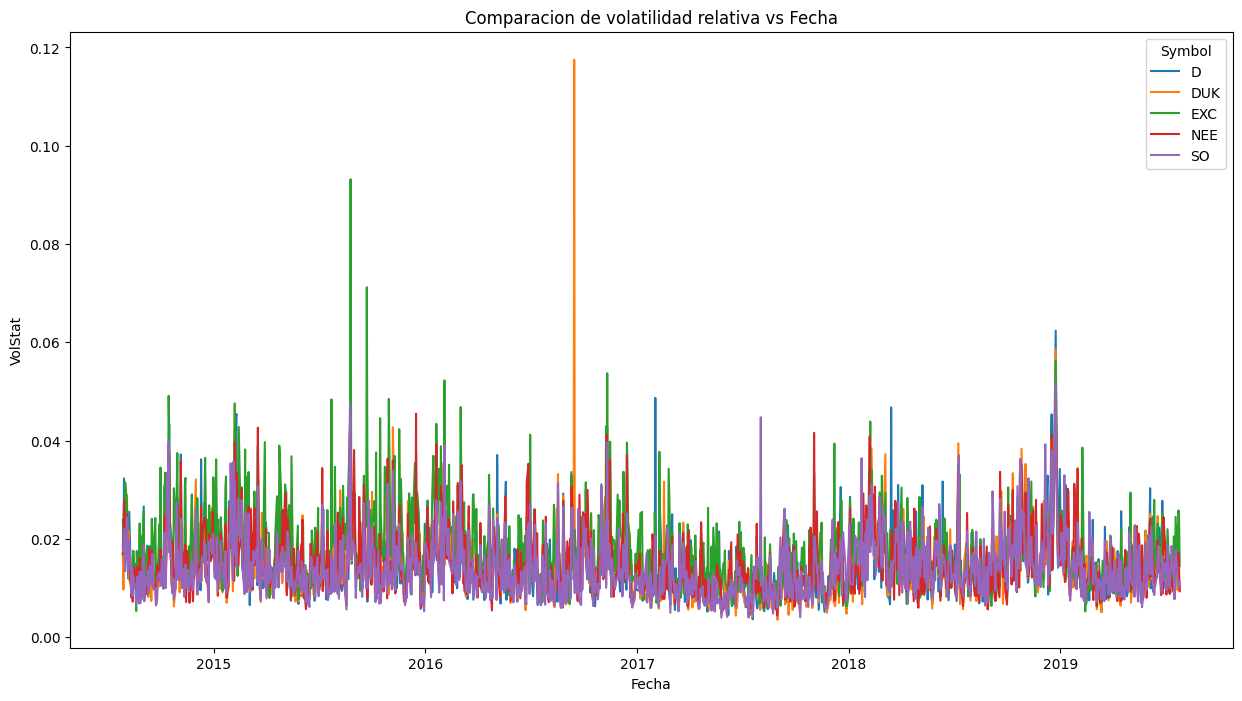

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(15,8))
sns.lineplot(x= agg_df1.Date, y= agg_df1.VolStat, hue=agg_df1.Symbol)
plt.xlabel('Fecha')
plt.ylabel('VolStat')
plt.title('Comparacion de volatilidad relativa vs Fecha');

In [ ]:
agg_df2=agg_df[['Date','Symbol','Return']].groupby(by=['Date','Symbol']).mean().reset_index()
agg_df2['Date']=pd.to_datetime(agg_df1['Date'])
agg_df2

,Date,Symbol,Return
0,2014-07-28,D,0.016201
1,2014-07-28,DUK,0.014732
2,2014-07-28,EXC,0.017192
3,2014-07-28,NEE,0.011272
4,2014-07-28,SO,0.016585
...,...,...,...
6290,2019-07-26,D,0.005620
6291,2019-07-26,DUK,0.004740
6292,2019-07-26,EXC,-0.009083
6293,2019-07-26,NEE,0.004949


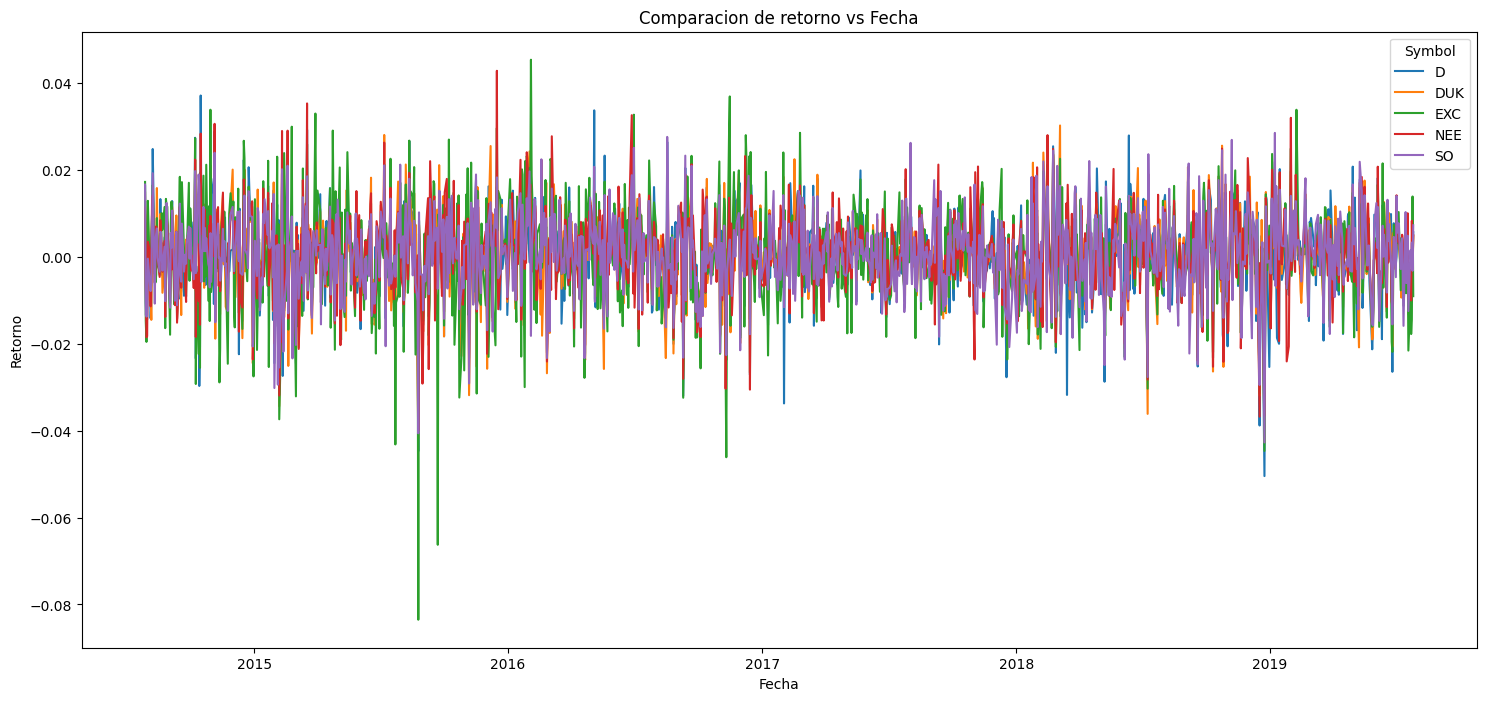

In [ ]:
plt.figure(figsize=(18,8))
sns.lineplot(x= agg_df2.Date, y= agg_df2.Return, hue=agg_df2.Symbol)
plt.xlabel('Fecha')
plt.ylabel('Retorno')
plt.title('Comparacion de retorno vs Fecha');

Vamos a traer ámbos gráficos en un mismo canvas para compararlos más facilmente, haciendo uso de los subplots de matplotlib

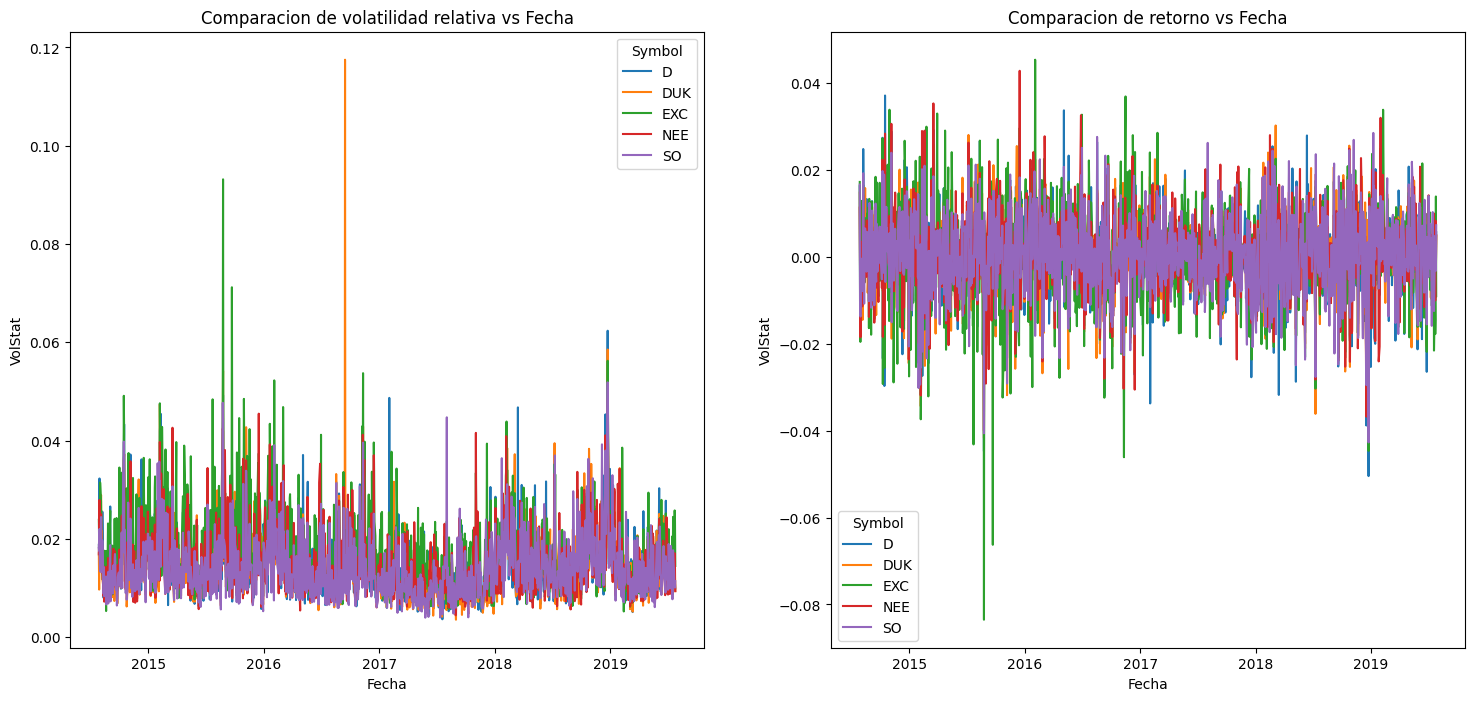

In [ ]:
plt.figure(figsize=(18,8))
plt.subplot(121)
sns.lineplot(x= agg_df1.Date, y= agg_df1.VolStat, hue=agg_df1.Symbol)
plt.xlabel('Fecha')
plt.ylabel('VolStat')
plt.title('Comparacion de volatilidad relativa vs Fecha')
plt.subplot(122)
sns.lineplot(x= agg_df2.Date, y= agg_df2.Return, hue=agg_df2.Symbol)
plt.xlabel('Fecha')
plt.ylabel('VolStat')
plt.title('Comparacion de retorno vs Fecha');

Donde invertirian?


Cada acción exhibe un **agrupamiento de volatilidad**: los períodos de alta volatilidad tienden a agruparse. Cada una de las acciones experimentó una alta volatilidad en momentos relativamente similares, lo que sugiere que algún factor de mercado más amplio puede estar afectando al sector energético.

## Manipulación Outliers

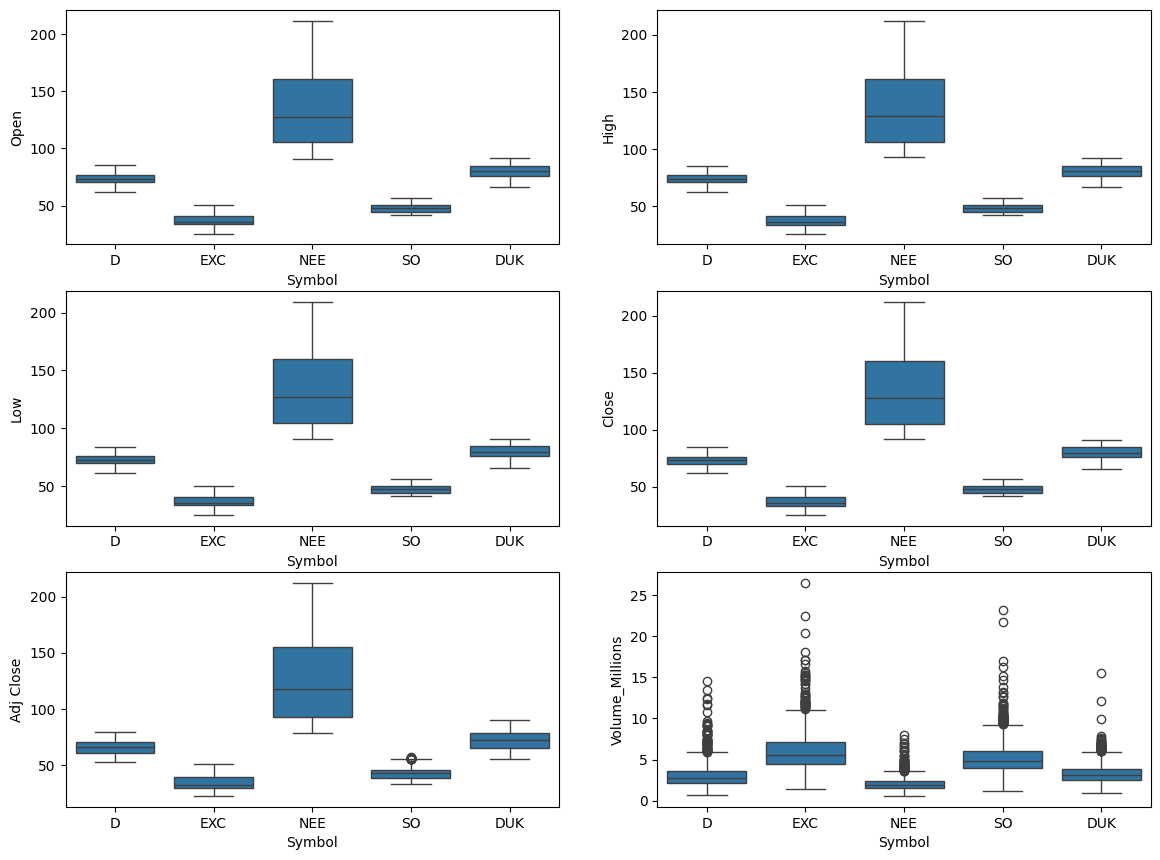

In [ ]:
# Seleccionar las columnas de interes
# Creamos la lista de columnas de interés excluyendo ahora si 'Date' y 'Volume'
l=[x for x in agg_df.columns if x not in ['Date','Volume']]
# Definimos el tamaño de nuestra figura 14x14 pulgadas
plt.figure(figsize=(14,14))
#iteramos sobre las columnas seleccionadas, con zip emparejamos los indices de cada columna
for x,column in zip(range(8),agg_df[l]):
  if column !='Symbol':# evitamos graficar 'Symbol' porque esa es la columna clave
    #print(x)
    if x<=5:# limitamos a los primeros 6 gráficos (los indices arrancan de 0 no se olviden nunca!)
      plt.subplot(4,2,x+1)# creamos la grilla de gráficos, filas columnas, x+1 por matplotlib arranca de 1 y x de 0. asi los emparejamos
      sns.boxplot(data=agg_df[l], y=column, x=agg_df[l]['Symbol'])# dibujamos un grafico de caja para cada variable en eje Y y agrupamos por symbol

# IQR (Rango Intercuartílico)

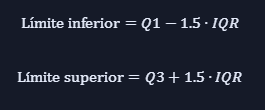

IQR = Q3-Q1  
Lim inf = Q1 - (1.5 x IQR)  
Lim Sup = Q3 + (1.5 x IQR)  

In [ ]:
l=[x for x in agg_df.columns if x not in ['Date','Volume','Symbol']]
datos= agg_df[l]
datos.head()

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return
0,69.750000,71.059998,69.750000,70.879997,57.963978,1.8064,0.018781,0.016201
1,70.669998,70.980003,69.930000,69.930000,57.187099,2.2311,0.014858,-0.010471
2,70.000000,70.660004,68.400002,68.970001,56.402020,2.5889,0.032286,-0.014714
3,68.629997,68.849998,67.580002,67.639999,55.314388,3.2669,0.018505,-0.014425
4,67.330002,68.410004,67.220001,67.589996,55.273487,2.6018,0.017674,0.003861


In [ ]:
agg_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6295 entries, 0 to 1258
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             6295 non-null   object 
 1   Open             6295 non-null   float64
 2   High             6295 non-null   float64
 3   Low              6295 non-null   float64
 4   Close            6295 non-null   float64
 5   Adj Close        6295 non-null   float64
 6   Volume           6295 non-null   int64  
 7   Volume_Millions  6295 non-null   float64
 8   Symbol           6295 non-null   object 
 9   VolStat          6295 non-null   float64
 10  Return           6295 non-null   float64
dtypes: float64(8), int64(1), object(2)
memory usage: 719.2+ KB


Ahora graficamos las cajas, con los datos completos , si diferenciar el Symbolos de la acción. Para ver donde tenemos los outliers de cada variable con el método IQR que usa por defecto el boxplot (grafico de caja)

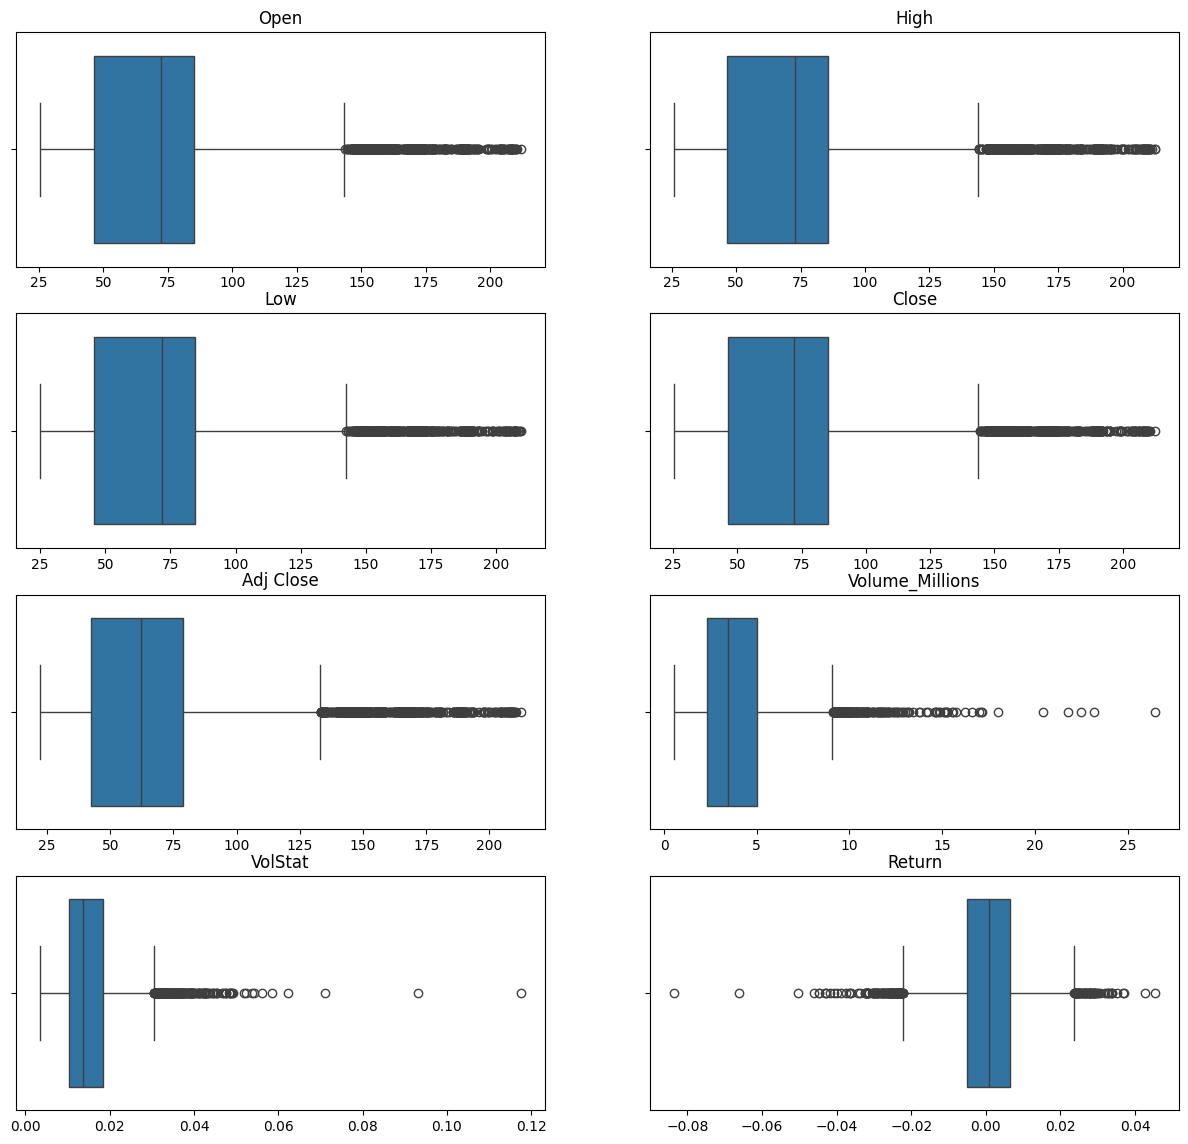

In [ ]:
plt.figure(figsize=(15,14))
for i,j in zip(range(8),datos.columns):
  plt.subplot(4,2,i+1)
  sns.boxplot(x=datos[j])
  plt.title(j)
  plt.xlabel('')

# Z score

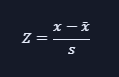

Vamos a calcular el z-score para la empresa 'D'

In [ ]:
# Cargar datos
datos= agg_df[agg_df['Symbol']=='D']
l=[x for x in agg_df.columns if x not in ['Volume','Symbol']]
datos=datos[l]
datos['Date']=pd.to_datetime(datos['Date'])
datos.head()

,Date,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return
0,2014-07-28,69.750000,71.059998,69.750000,70.879997,57.963978,1.8064,0.018781,0.016201
1,2014-07-29,70.669998,70.980003,69.930000,69.930000,57.187099,2.2311,0.014858,-0.010471
2,2014-07-30,70.000000,70.660004,68.400002,68.970001,56.402020,2.5889,0.032286,-0.014714
3,2014-07-31,68.629997,68.849998,67.580002,67.639999,55.314388,3.2669,0.018505,-0.014425
4,2014-08-01,67.330002,68.410004,67.220001,67.589996,55.273487,2.6018,0.017674,0.003861


In [ ]:
# Convertir a z score
datos_z=pd.DataFrame()
for j in datos.columns[1:]:# arrancamos desde 1 para saltear el indice 0, q es la fecha
  datos_z[j] = (datos[j] - datos[j].mean()) / datos[j].std()
datos_z['Fecha']= datos.Date
datos_z.head()

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return,Fecha
0,-0.836681,-0.653586,-0.705650,-0.572660,-1.367431,-0.827558,0.602511,1.660499,2014-07-28
1,-0.616990,-0.672802,-0.662563,-0.799816,-1.498234,-0.553347,0.003335,-1.131735,2014-07-29
2,-0.776982,-0.749671,-1.028803,-1.029364,-1.630418,-0.322331,2.664832,-1.575938,2014-07-30
3,-1.104132,-1.184460,-1.225089,-1.347384,-1.813542,0.115425,0.560306,-1.545671,2014-07-31
4,-1.414564,-1.290153,-1.311264,-1.359340,-1.820429,-0.314002,0.433434,0.368729,2014-08-01


Generemos una nueva columna categórica que indique si es un valor típico, o atípico (inlier u outlier)

In [ ]:
datos_z['Open_x']= datos_z['Open'].apply(lambda x: 'Atipico' if (x>2 or x<-2) else 'Normal')
datos_z.head()

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return,Fecha,Open_x
0,-0.836681,-0.653586,-0.705650,-0.572660,-1.367431,-0.827558,0.602511,1.660499,2014-07-28,Normal
1,-0.616990,-0.672802,-0.662563,-0.799816,-1.498234,-0.553347,0.003335,-1.131735,2014-07-29,Normal
2,-0.776982,-0.749671,-1.028803,-1.029364,-1.630418,-0.322331,2.664832,-1.575938,2014-07-30,Normal
3,-1.104132,-1.184460,-1.225089,-1.347384,-1.813542,0.115425,0.560306,-1.545671,2014-07-31,Normal
4,-1.414564,-1.290153,-1.311264,-1.359340,-1.820429,-0.314002,0.433434,0.368729,2014-08-01,Normal


Ya que tenemos los datos convertidos y nuetsra variable que nos marca los outliers, grafiquemos a ver que nos encontramos.

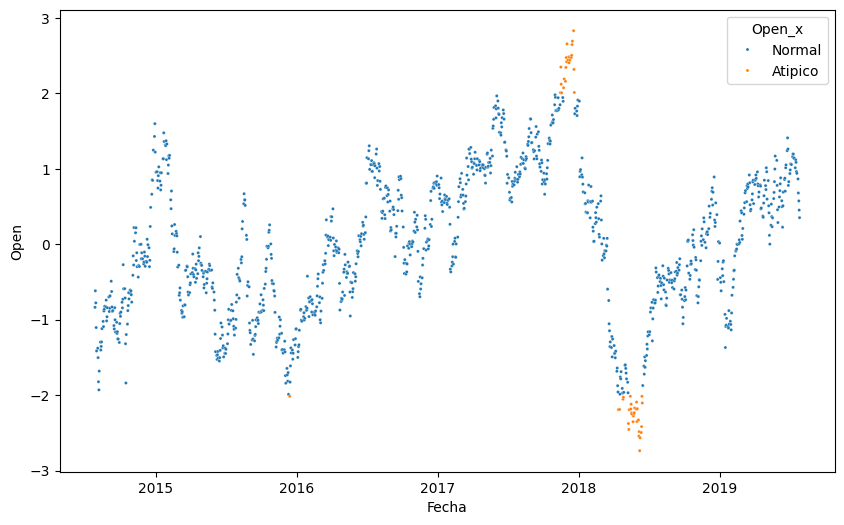

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x=datos_z.Fecha, y= datos_z.Open, hue= datos_z['Open_x'],s= 5);#grafico simple de disperción, le pasamos open_X para diferenciar por colores.

# Distancia multiple

In [ ]:
# Extraer columnas de interes
data_multiple=datos_z.drop(columns=['Open_x','Fecha'])# tiramos la columna que generamos para el método anterior
data_multiple.head()

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return
0,-0.836681,-0.653586,-0.705650,-0.572660,-1.367431,-0.827558,0.602511,1.660499
1,-0.616990,-0.672802,-0.662563,-0.799816,-1.498234,-0.553347,0.003335,-1.131735
2,-0.776982,-0.749671,-1.028803,-1.029364,-1.630418,-0.322331,2.664832,-1.575938
3,-1.104132,-1.184460,-1.225089,-1.347384,-1.813542,0.115425,0.560306,-1.545671
4,-1.414564,-1.290153,-1.311264,-1.359340,-1.820429,-0.314002,0.433434,0.368729


Como el método de distancia múltiple mide justamente distancias sería mejor normalizar los datos para trabajar en 1 misma escala.  
Usamos la distancia Euclideana basado en Z-Score  
Fórmula de cálculo de la distancia Euclideana  
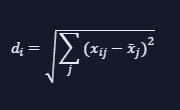

In [ ]:
def outlier_euclideano_d(x,cutoff):
  # x: dataframe con valores numericos normalizados
  result_ = pd.Series([0] * len(x.iloc[:,1]))# creamos una pd.Series de Ceros para marcar los no outliers para todas las filas/registros
  data_mean = x.mean() # media de los datos_
  dist = np.sqrt(np.sum(((x-data_mean) ** 2),axis=1))# calculamos la distancia euclideana
  dist_mean = dist.mean()# ahora la media de las distancia
  dist_zscore = np.abs((dist - dist_mean) / dist.std())# formula de z-score para las distancias
  result_[((dist_zscore > cutoff))] = 1# si el z-score es mayor a 3, lo marcará como outlier con un 1. usamos 3 proque es el criterio clásico para extremos.
  return result_

In [ ]:
# Crear una copia de los datos
euc_d = data_multiple.copy()
euc_d.head()

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return
0,-0.836681,-0.653586,-0.705650,-0.572660,-1.367431,-0.827558,0.602511,1.660499
1,-0.616990,-0.672802,-0.662563,-0.799816,-1.498234,-0.553347,0.003335,-1.131735
2,-0.776982,-0.749671,-1.028803,-1.029364,-1.630418,-0.322331,2.664832,-1.575938
3,-1.104132,-1.184460,-1.225089,-1.347384,-1.813542,0.115425,0.560306,-1.545671
4,-1.414564,-1.290153,-1.311264,-1.359340,-1.820429,-0.314002,0.433434,0.368729


In [ ]:
# Aplicar la funcion
euc_d['outlier']=outlier_euclideano_d(euc_d,2)# si le pasamos 2 al cutoff seremos más estrictos y obtendremos más outliers
euc_d.head()

,Open,High,Low,Close,Adj Close,Volume_Millions,VolStat,Return,outlier
0,-0.836681,-0.653586,-0.705650,-0.572660,-1.367431,-0.827558,0.602511,1.660499,0
1,-0.616990,-0.672802,-0.662563,-0.799816,-1.498234,-0.553347,0.003335,-1.131735,0
2,-0.776982,-0.749671,-1.028803,-1.029364,-1.630418,-0.322331,2.664832,-1.575938,0
3,-1.104132,-1.184460,-1.225089,-1.347384,-1.813542,0.115425,0.560306,-1.545671,0
4,-1.414564,-1.290153,-1.311264,-1.359340,-1.820429,-0.314002,0.433434,0.368729,0


In [ ]:
euc_d.shape

(1259, 9)

In [ ]:
(euc_d['outlier']==1).sum()

np.int64(58)

Grafiquemos a ver como quedaron los outliers en las distitnas variables con éste método

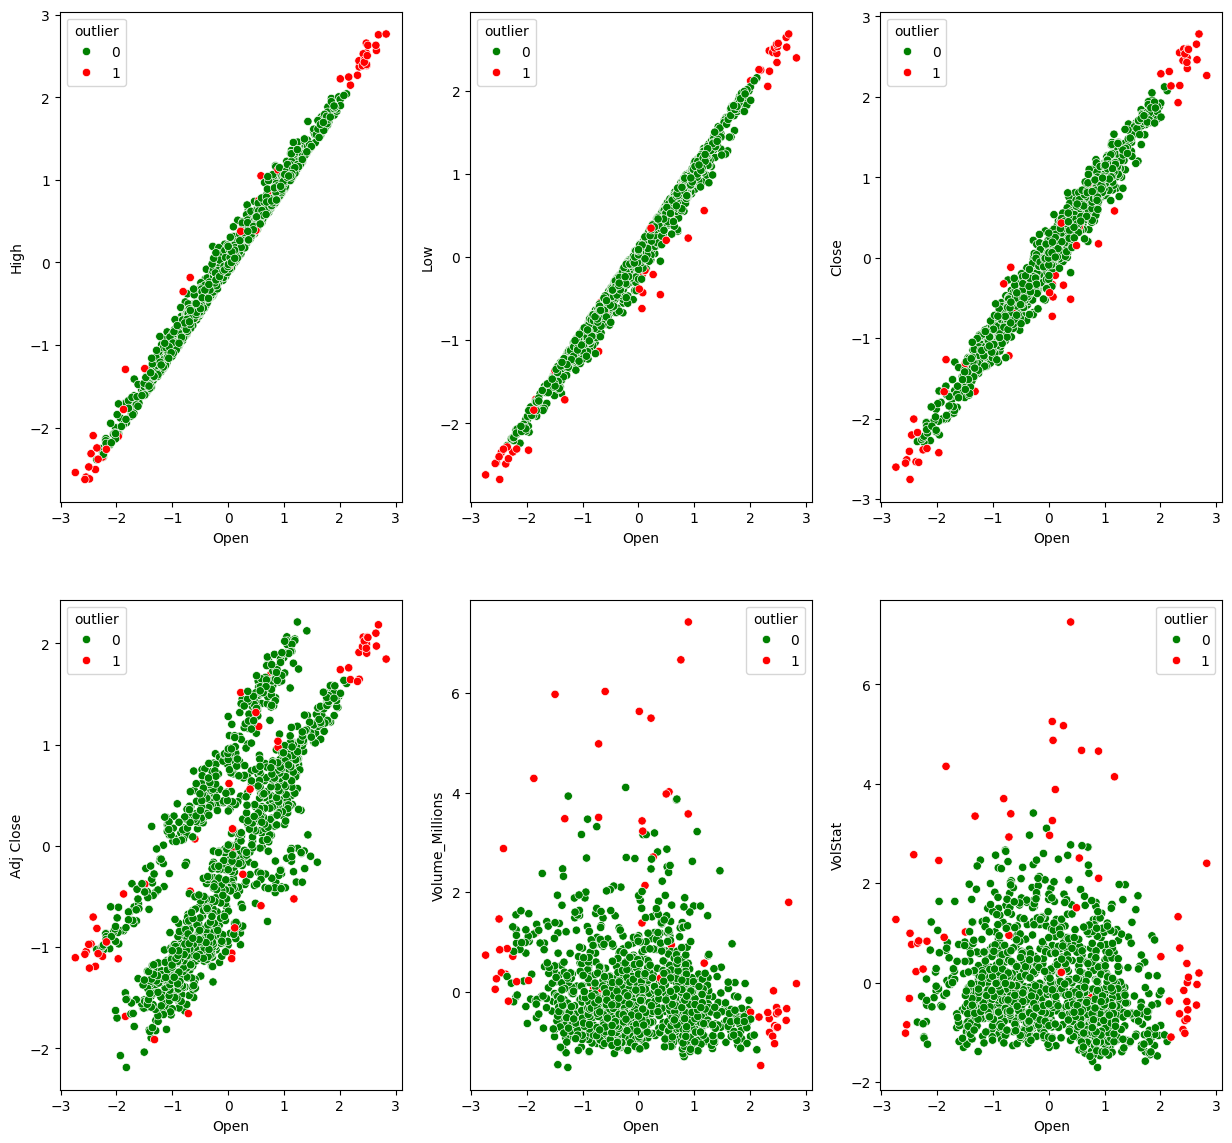

In [ ]:
plt.figure(figsize=(15,14))
plt.subplot(2,3,1)# filas, columnas y donde pone la 1er figura, recuerden que matplotlib arranca sus indices de 1.
sns.scatterplot(x="Open",y="High",data=euc_d,hue="outlier",palette=["green","red"])
plt.subplot(2,3,2)
sns.scatterplot(x="Open",y="Low",data=euc_d,hue="outlier",palette=["green","red"])
plt.subplot(2,3,3)
sns.scatterplot(x="Open",y="Close",data=euc_d,hue="outlier",palette=["green","red"])
plt.subplot(2,3,4)
sns.scatterplot(x="Open",y="Adj Close",data=euc_d,hue="outlier",palette=["green","red"])
plt.subplot(2,3,5)
sns.scatterplot(x="Open",y="Volume_Millions",data=euc_d,hue="outlier",palette=["green","red"])
plt.subplot(2,3,6)
sns.scatterplot(x="Open",y="VolStat",data=euc_d,hue="outlier",palette=["green","red"]);

# Imputacion

In [ ]:
url='https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv'
df= pd.read_csv(url,sep=',', header=None)
print(df.shape)
df.replace(0, np.nan, inplace=True)
df.head()

(768, 9)


,0,1,2,3,4,5,6,7,8
0,6.0,148.0,72.0,35.0,NaN,33.6,0.627,50,1.0
1,1.0,85.0,66.0,29.0,NaN,26.6,0.351,31,NaN
2,8.0,183.0,64.0,NaN,NaN,23.3,0.672,32,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21,NaN
4,NaN,137.0,40.0,35.0,168.0,43.1,2.288,33,1.0


In [ ]:
# reemplazar con la mediana
from sklearn.impute import SimpleImputer

valores = df.values #numpy array con los valores
imputador = SimpleImputer(missing_values=np.nan, strategy='median')# instanciar el imputador y decidimos la estrategia de imputación (la mediana) 'mean', mode
# transformar el dataset
transformados = imputador.fit_transform(valores)# acá hacemos correr el imputador
transformados=pd.DataFrame(transformados)# acá lo convertimos a dataframe, porque el imputador nos devuelve un numpy array
transformados.head().round(2)

,0,1,2,3,4,5,6,7,8
0,6.0,148.0,72.0,35.0,125.0,33.6,0.63,50.0,1.0
1,1.0,85.0,66.0,29.0,125.0,26.6,0.35,31.0,1.0
2,8.0,183.0,64.0,29.0,125.0,23.3,0.67,32.0,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.17,21.0,1.0
4,4.0,137.0,40.0,35.0,168.0,43.1,2.29,33.0,1.0


# Interpolacion

In [ ]:
# pisamos los datos, para recuperar los nan
url='https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv'
df= pd.read_csv(url,sep=',', header=None)
print(df.shape)
df.replace(0, np.nan, inplace=True)
print(df.head().round(2))

(768, 9)
     0      1     2     3      4     5     6   7    8
0  6.0  148.0  72.0  35.0    NaN  33.6  0.63  50  1.0
1  1.0   85.0  66.0  29.0    NaN  26.6  0.35  31  NaN
2  8.0  183.0  64.0   NaN    NaN  23.3  0.67  32  1.0
3  1.0   89.0  66.0  23.0   94.0  28.1  0.17  21  NaN
4  NaN  137.0  40.0  35.0  168.0  43.1  2.29  33  1.0


Interpolación Lineal  
Usando el método interpolate de pandas
Busca los nan en las columnas numéricas y los reemplaza calculando un valor intermedio proporcional entre los datos vecinos  
ejemplo: si tenes [10,nan,30] el valor faltante con éste método será rellenado con 20

In [ ]:
print(df.interpolate(method="linear").head().round(2))# recibe como argumento el método a utiliar 'linear' para este caso.

     0      1     2     3      4     5     6   7    8
0  6.0  148.0  72.0  35.0    NaN  33.6  0.63  50  1.0
1  1.0   85.0  66.0  29.0    NaN  26.6  0.35  31  1.0
2  8.0  183.0  64.0  26.0    NaN  23.3  0.67  32  1.0
3  1.0   89.0  66.0  23.0   94.0  28.1  0.17  21  1.0
4  3.0  137.0  40.0  35.0  168.0  43.1  2.29  33  1.0


El método polinomial en vez de dibujar una linea recta entre los puntos, dibuja una curva ajustada por el orden, cuadrática o cúbica. Puede capturar tendencias más complejas, pero es más suceptible al ruido (como outliers por ejemplo).

In [ ]:
print(df.interpolate(method="polynomial",order=2).head().round(2))# acá probamos con polinomial de orden 2 (cuadrático) en 3 sería cúbico.

      0      1     2      3      4     5     6   7    8
0  6.00  148.0  72.0  35.00    NaN  33.6  0.63  50  1.0
1  1.00   85.0  66.0  29.00    NaN  26.6  0.35  31  1.0
2  8.00  183.0  64.0  22.36    NaN  23.3  0.67  32  1.0
3  1.00   89.0  66.0  23.00   94.0  28.1  0.17  21  1.0
4  1.96  137.0  40.0  35.00  168.0  43.1  2.29  33  1.0


Nearest usa el valor más cercano para la interpolación. Copia el dato más cercano en el índice, hacia arriba o hacia abajo y lo asigna al nan.  
Es ideal cuando son valores discretos o categóricos donde no tiene sentido rellenar con valores decimales. (ejemplo puertas de un vehiculo)

In [ ]:
df.interpolate(method='nearest')

,0,1,2,3,4,5,6,7,8
0,6.0,148.0,72.0,35.0,NaN,33.6,0.627,50,1.0
1,1.0,85.0,66.0,29.0,NaN,26.6,0.351,31,1.0
2,8.0,183.0,64.0,29.0,NaN,23.3,0.672,32,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21,1.0
4,1.0,137.0,40.0,35.0,168.0,43.1,2.288,33,1.0
...,...,...,...,...,...,...,...,...,...
763,10.0,101.0,76.0,48.0,180.0,32.9,0.171,63,1.0
764,2.0,122.0,70.0,27.0,180.0,36.8,0.340,27,1.0
765,5.0,121.0,72.0,23.0,112.0,26.2,0.245,30,1.0
766,1.0,126.0,60.0,23.0,NaN,30.1,0.349,47,1.0


# Datawig  
se rompió la libreria ⛔ T_T  
vamos a hacerlo con scikit-learn

In [ ]:
#!pip install datawig

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.5/61.5 kB 2.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 59.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 93.5 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


In [ ]:
df.columns= ['Col0','Col1','Col2','Col3','Col4','Col5','Col6','Col7','Col8']
df.head()

,Col0,Col1,Col2,Col3,Col4,Col5,Col6,Col7,Col8
0,6.0,148.0,72.0,35.0,NaN,33.6,0.627,50,1.0
1,1.0,85.0,66.0,29.0,NaN,26.6,0.351,31,NaN
2,8.0,183.0,64.0,NaN,NaN,23.3,0.672,32,1.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21,NaN
4,NaN,137.0,40.0,35.0,168.0,43.1,2.288,33,1.0


In [ ]:
"""import datawig
import pandas as pd
import datawig

df_train, df_test = datawig.utils.random_split(df)

#Inicializar el modelo SimpleImputer
imputer = datawig.SimpleImputer(
    input_columns=['Col0','Col1','Col2'], # columnas que tienen la informacion con la columna a imputar
    output_column= 'Col4', # columna que queremos imputar
    output_path = 'imputer_model' # modelo y metricas
    )
"""

In [ ]:
"""
# Entrenar el modelo con data de entrenamiento y 50 epocas
imputer.fit(train_df=df_train, num_epochs=50)

# Imputar los missing values y devolver el dataframe original con la predicciones
imputed = imputer.predict(df_test)
"""


2021-12-30 22:51:04,907 [INFO]  
========== start: fit model
2021-12-30 22:51:04,915 [WARNING]  Already bound, ignoring bind()
2021-12-30 22:51:04,965 [INFO]  Epoch[0] Batch [0-18]	Speed: 8211.21 samples/sec	cross-entropy=18.778674	Col4-accuracy=8.578947
2021-12-30 22:51:05,010 [INFO]  Epoch[0] Train-cross-entropy=18.152885
2021-12-30 22:51:05,017 [INFO]  Epoch[0] Train-Col4-accuracy=8.085714
2021-12-30 22:51:05,022 [INFO]  Epoch[0] Time cost=0.097
2021-12-30 22:51:05,041 [INFO]  Saved checkpoint to "imputer_model/model-0000.params"
2021-12-30 22:51:05,052 [INFO]  Epoch[0] Validation-cross-entropy=32.327998
2021-12-30 22:51:05,058 [INFO]  Epoch[0] Validation-Col4-accuracy=0.000000
2021-12-30 22:51:05,103 [INFO]  Epoch[1] Batch [0-18]	Speed: 7942.87 samples/sec	cross-entropy=15.598518	Col4-accuracy=8.578947
2021-12-30 22:51:05,146 [INFO]  Epoch[1] Train-cross-entropy=15.708923
2021-12-30 22:51:05,153 [INFO]  Epoch[1] Train-Col4-accuracy=8.085714
2021-12-30 22:51:05,159 [INFO]  Epoch[1] 

In [ ]:
imputed

,Col0,Col1,Col2,Col3,Col4,Col5,Col6,Col7,Col8,Col4_imputed
734,2.0,105.0,75.0,NaN,NaN,23.3,0.560,53,NaN,113.497543
213,NaN,140.0,65.0,26.0,130.0,42.6,0.431,24,1.0,175.098219
465,NaN,124.0,56.0,13.0,105.0,21.8,0.452,21,NaN,149.183241
206,8.0,196.0,76.0,29.0,280.0,37.5,0.605,57,1.0,168.510320
762,9.0,89.0,62.0,NaN,NaN,22.5,0.142,33,NaN,110.740118
...,...,...,...,...,...,...,...,...,...,...
123,5.0,132.0,80.0,NaN,NaN,26.8,0.186,69,NaN,166.950378
369,1.0,133.0,102.0,28.0,140.0,32.8,0.234,45,1.0,115.384075
320,4.0,129.0,60.0,12.0,231.0,27.5,0.527,31,NaN,158.350257
527,3.0,116.0,74.0,15.0,105.0,26.3,0.107,24,NaN,136.906594


In [ ]:
print(imputed.head(20).round(2))

     Col0   Col1  Col2  Col3   Col4  Col5  Col6  Col7  Col8  Col4_imputed
734   2.0  105.0  75.0   NaN    NaN  23.3  0.56    53   NaN        113.50
213   NaN  140.0  65.0  26.0  130.0  42.6  0.43    24   1.0        175.10
465   NaN  124.0  56.0  13.0  105.0  21.8  0.45    21   NaN        149.18
206   8.0  196.0  76.0  29.0  280.0  37.5  0.60    57   1.0        168.51
762   9.0   89.0  62.0   NaN    NaN  22.5  0.14    33   NaN        110.74
542  10.0   90.0  85.0  32.0    NaN  34.9  0.82    56   1.0        108.02
255   1.0  113.0  64.0  35.0    NaN  33.6  0.54    21   1.0        130.35
412   1.0  143.0  84.0  23.0  310.0  42.4  1.08    22   NaN        146.46
328   2.0  102.0  86.0  36.0  120.0  45.5  0.13    23   1.0        121.36
583   8.0  100.0  76.0   NaN    NaN  38.7  0.19    42   NaN        131.35
346   1.0  139.0  46.0  19.0   83.0  28.7  0.65    22   NaN        164.06
427   1.0  181.0  64.0  30.0  180.0  34.1  0.33    38   1.0        215.98
649   NaN  107.0  60.0  25.0    NaN  2

## Entrenaremos un modelo de regresión con scikit-learn
éste es el método más inteligente para imputar ya que encuentra las relaciones entre las variables.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Cargar dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
cols = ["preg", "plas", "pres", "skin", "insulin", "mass", "pedi", "age", "class"]# nombramos las columnas
df = pd.read_csv(url, names=cols)
df.head()

,preg,plas,pres,skin,insulin,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
# Supongamos que queremos imputar la columna 'insulin'
# (en este dataset hay muchos ceros que se interpretan como valores faltantes)
df["insulin"] = df["insulin"].replace(0, np.nan)

# Separar train (sin NaN en insulin) y test (con NaN en insulin)
train = df.dropna(subset=["insulin"])
test = df[df["insulin"].isna()]

# Seaparamos las variables predictoras de la variable target (la que queremso predecir)
X_train = train.drop(columns=["insulin"])
y_train = train["insulin"]

# en X_test tmb dropeamos la variable target
X_test = test.drop(columns=["insulin"])

Ya tenemos los datos listos para modelar.  
Ahora vamos a usar un modelo de los tantos que hay, podriamos ir por cosas super simples como una regresion lineal, KNN, arbol de decisión... pero para este caso vamso con random forest que es un modelo derivado de los arboles de decisión

In [ ]:
# Entrenar modelo para predecir 'insulin' con un modelo basado en arboles (más sobre ésto en las clases de modelado)
model = RandomForestRegressor(random_state=42)# instanciamos el modelo
model.fit(X_train, y_train)# entrenamos el modelo con nuestros datos.

# Imputar valores faltantes
df.loc[df["insulin"].isna(), "insulin"] = model.predict(X_test)# localizamos los nan de nuestra variable insulin en nuestor df y llenamos esa variable con lo que devuelva el modelo

print(df.head(10))


   preg  plas  pres  skin  insulin  mass   pedi  age  class
0     6   148    72    35   175.33  33.6  0.627   50      1
1     1    85    66    29    49.08  26.6  0.351   31      0
2     8   183    64     0   275.41  23.3  0.672   32      1
3     1    89    66    23    94.00  28.1  0.167   21      0
4     0   137    40    35   168.00  43.1  2.288   33      1
5     5   116    74     0   151.23  25.6  0.201   30      0
6     3    78    50    32    88.00  31.0  0.248   26      1
7    10   115     0     0   184.23  35.3  0.134   29      0
8     2   197    70    45   543.00  30.5  0.158   53      1
9     8   125    96     0   275.77   0.0  0.232   54      1


Veamos para comparar los 3 primeros registros de insulin con los distintos métodos que vimos  

Método imputacion con mediana: 125,125,125  
Método Interpolate (lineal, polinomial y nearest):nan,nan,nan  
Método Random Forest:175.33,49.08,275.41  

| Método de imputación | Descripción | Ejemplo de valor imputado (fila con NaN en ``insulin``) | Ventajas | Desventajas |
| --- | --- | --- | --- | --- |
| **Media** | Reemplaza NaN con el promedio de la columna. | ``insulin ``= 125`` | Simple, rápido, siempre funciona. | Ignora relaciones entre variables, puede distorsionar la distribución. |
| **Interpolación lineal** | Calcula valores intermedios en línea recta entre vecinos. | ``insulin ``= ``nan`` (no tenia valores cercanos para imputar) | Respeta la tendencia local de los datos. | Solo útil si los datos tienen orden temporal o secuencial. |
| **Modelado (Random Forest)** | Entrena un modelo con otras variables (``preg``, ``plas``, ``mass``, etc.) para predecir ``insulin``. | ``insulin ``= ``175.33`` (predicho por el modelo) | Usa relaciones multivariadas, más realista. | Requiere entrenamiento, más complejo, sensible al modelo elegido. |

# Correlaciones de perason
La correlación es una medida estadística que indica el grado y la dirección de la relación entre dos variables.  
  
Correlación positiva: cuando una variable aumenta, la otra también tiende a aumentar.  
Correlación negativa: cuando una aumenta, la otra tiende a disminuir.  
Correlación nula o cercana a 0: no existe una relación clara entre ellas.  
  
Los coeficientes de correlación suelen tomar valores entre -1 y 1:  
  
1 → relación positiva perfecta.  
0 → ausencia de relación.  
-1 → relación negativa perfecta.  

## Correlación de Pearson

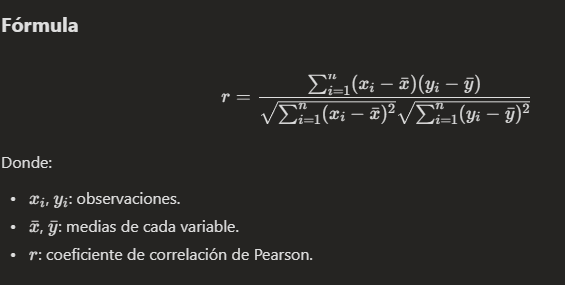

Cuándo usarla  
Relación aproximadamente lineal.  
Datos numéricos continuos.  
Es sensible a valores extremos (outliers).  

## Correlación de Spearman
Mide la realción monótona entre dos variables usando sus **rangos** en lugar de los valores originales.  

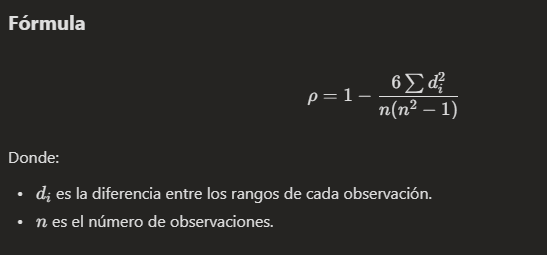

Cuándo usarla  
Cuando los datos no siguen una relación lineal.  
Cuando hay valores atípicos.  
Cuando se trabaja con rankings o posiciones.  
  
Ejemplo: relación entre la posición en un ranking de ventas y la satisfacción del cliente.  

---------
Regla práctica para Data Science  
Pearson → "¿Las variables se mueven linealmente juntas?"  
Spearman → "¿Cuando una sube, la otra tiende a subir, aunque no sea de forma lineal?"  

Por ejemplo, si estamos trabajando con precios de acciones, retornos financieros o indicadores de mercado en Pandas, lo más habitual es comenzar con Pearson (df.corr(method='pearson')) y luego contrastar con Spearman si sospechas relaciones no lineales. (df.corr(method='spearman'))

In [ ]:
df= pd.read_csv('https://raw.githubusercontent.com/JJTorresDS/stocks-ds-edu/main/stocks.csv')
df.index= df.formatted_date
df= df.drop(columns='formatted_date')
df.head()

,MCD,SBUX,GOOG,AMZN,MSFT,JPM,BAC,C,MAR,HLT,RCL,V,MA,PYPL
formatted_date,,,,,,,,,,,,,,
2016-01-01,106.332146,54.353962,742.950012,587.000000,49.853489,50.424938,12.573010,36.897804,57.754189,35.192841,74.235298,71.574371,85.822624,36.139999
2016-02-01,100.671043,52.064243,697.770020,552.520020,46.043667,48.033066,11.132540,33.707108,64.228912,41.061607,67.360649,69.556580,83.956566,38.139999
2016-03-01,108.782211,53.571442,744.950012,593.640015,50.339031,50.524323,12.021718,36.223217,67.336624,44.499886,74.790009,73.631477,91.278160,38.599998
2016-04-01,109.483307,50.457645,693.010010,659.590027,45.453705,53.919910,12.995729,40.153545,66.305466,43.716049,70.465584,74.363144,93.683258,39.180000
2016-05-01,105.648926,49.255203,735.719971,722.789978,48.306515,56.098225,13.201019,40.447887,62.474155,41.198154,70.456474,75.999847,92.817329,37.790001


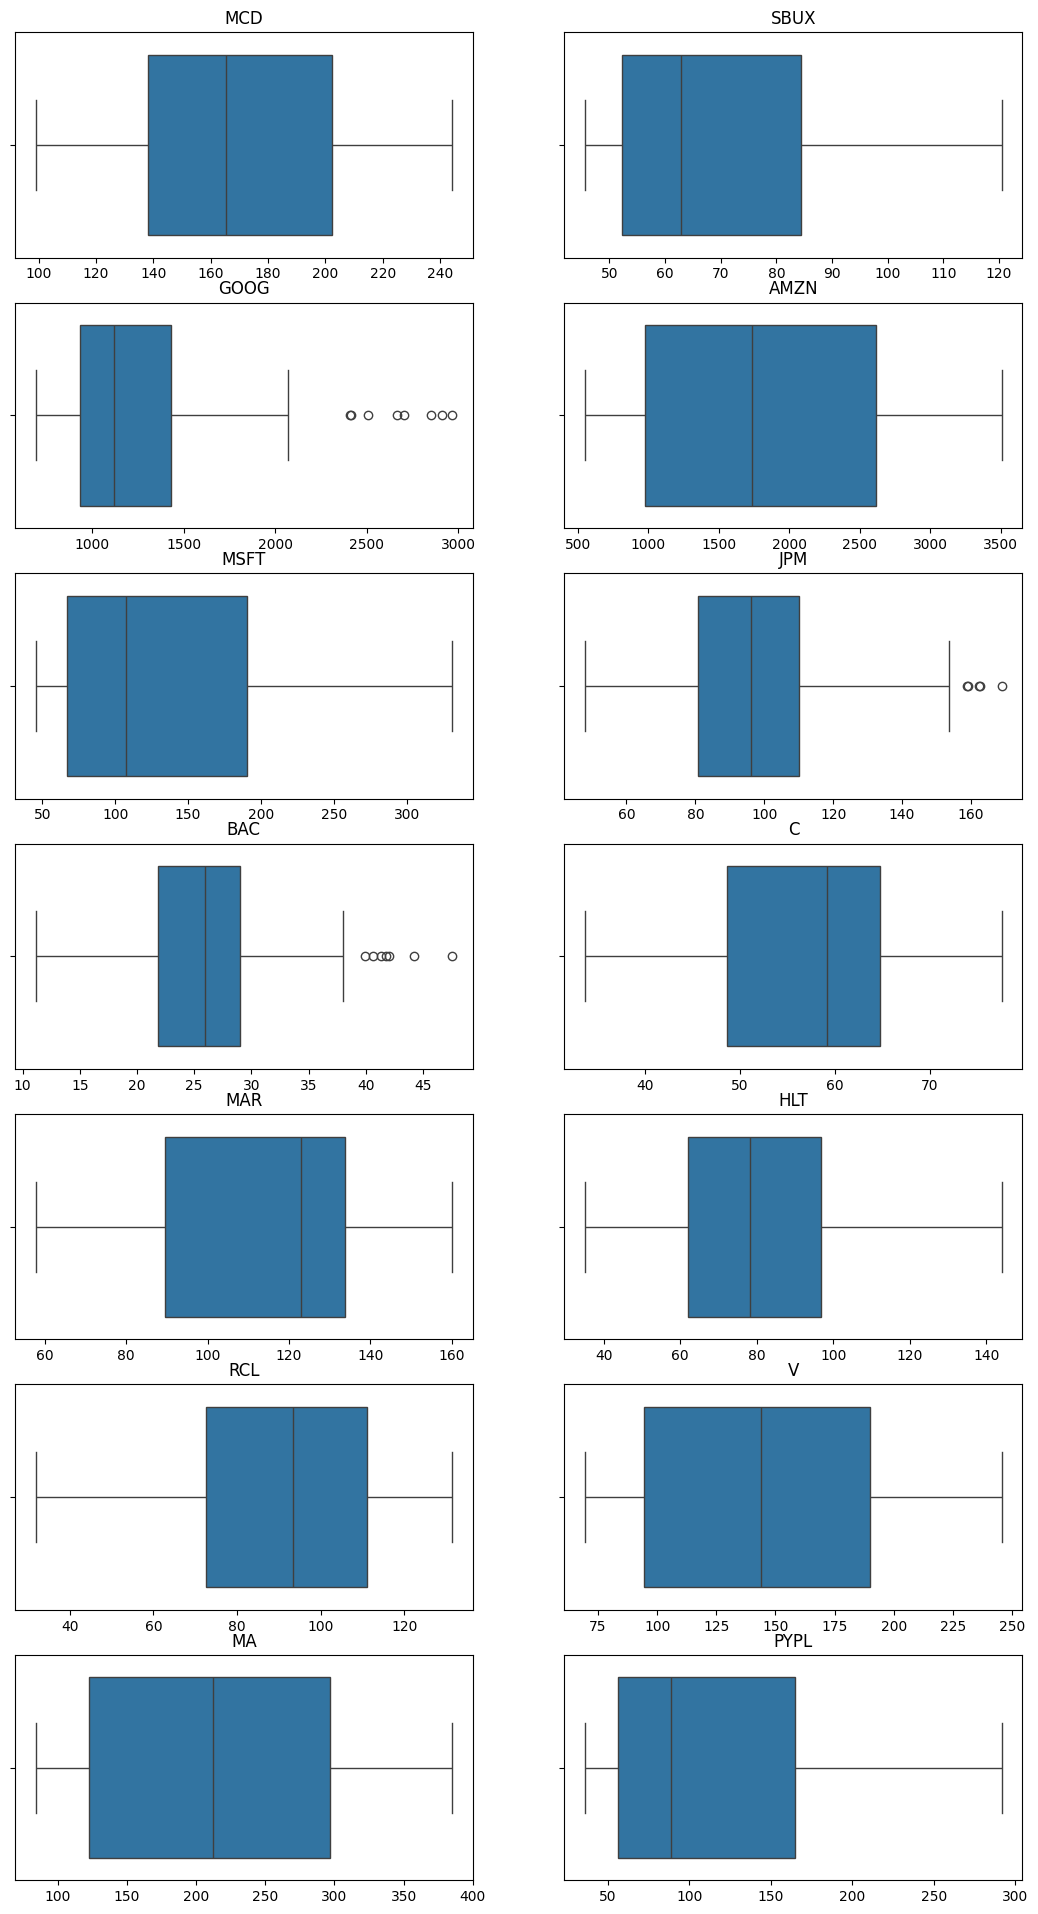

In [ ]:
# Outliers
plt.figure(figsize=(13,24))
for i,j in zip(range(14),df.columns):
  plt.subplot(7,2,i+1)
  sns.boxplot(x=df[j],orient='h')# si los queremos verticales, pasamos los datos al eje x en vez de y, y cambiamos el argumento orient a 'v'
  plt.title(j)
  plt.xlabel('');

In [ ]:
df.corr(method='pearson')

,MCD,SBUX,GOOG,AMZN,MSFT,JPM,BAC,C,MAR,HLT,RCL,V,MA,PYPL
MCD,1.000000,0.911649,0.872950,0.915207,0.921861,0.900587,0.857553,0.598726,0.758567,0.941815,0.052275,0.961073,0.956230,0.889973
SBUX,0.911649,1.000000,0.900343,0.874861,0.925871,0.854682,0.775915,0.463075,0.608303,0.895421,-0.138369,0.908692,0.907381,0.921438
GOOG,0.872950,0.900343,1.000000,0.898136,0.961937,0.909442,0.876196,0.530359,0.647768,0.905074,-0.130685,0.855338,0.841940,0.927271
AMZN,0.915207,0.874861,0.898136,1.000000,0.963040,0.831325,0.773567,0.414525,0.596446,0.859951,-0.207798,0.948422,0.951015,0.959953
MSFT,0.921861,0.925871,0.961937,0.963040,1.000000,0.873916,0.818282,0.436713,0.596887,0.897585,-0.232318,0.929751,0.926621,0.951394
JPM,0.900587,0.854682,0.909442,0.831325,0.873916,1.000000,0.982349,0.794576,0.872046,0.978772,0.202581,0.871820,0.859420,0.844586
BAC,0.857553,0.775915,0.876196,0.773567,0.818282,0.982349,1.000000,0.841762,0.899805,0.950060,0.292480,0.805341,0.789793,0.773794
C,0.598726,0.463075,0.530359,0.414525,0.436713,0.794576,0.841762,1.000000,0.913796,0.740547,0.686983,0.531859,0.510164,0.439464
MAR,0.758567,0.608303,0.647768,0.596446,0.596887,0.872046,0.899805,0.913796,1.000000,0.871625,0.581135,0.692143,0.679711,0.580950
HLT,0.941815,0.895421,0.905074,0.859951,0.897585,0.978772,0.950060,0.740547,0.871625,1.000000,0.170140,0.912165,0.905176,0.862439


<Axes: >

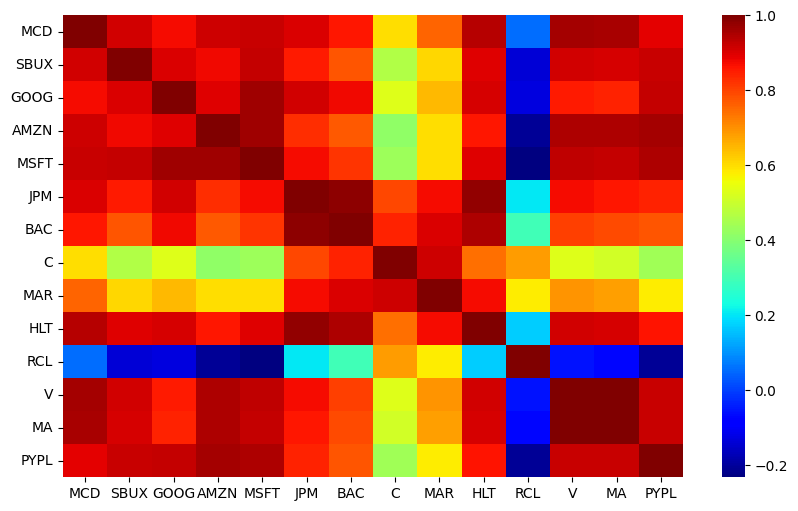

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(data=df.corr(method='pearson'), cmap='jet')

<Axes: >

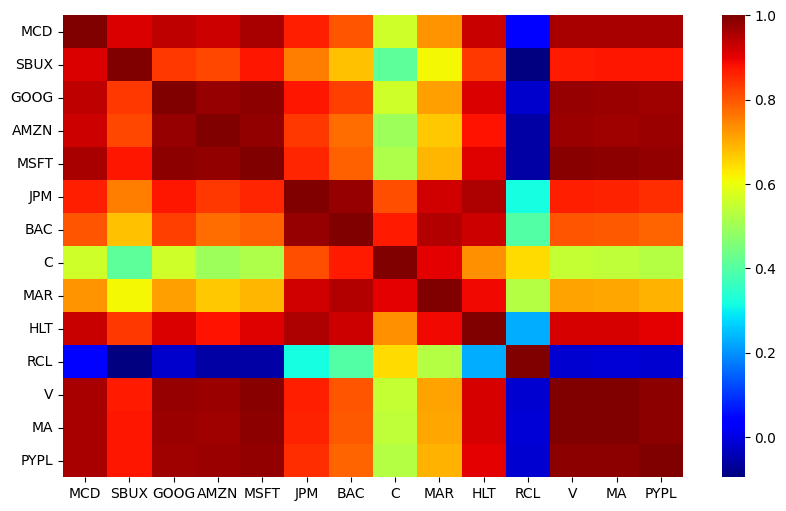

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(data=df.corr(method='spearman'), cmap='jet')

In [ ]:
def parejas(df):
    """
    Genera un conjunto (set) con las parejas de variables
    que pertenecen a la diagonal y al triángulo inferior
    de una matriz de correlación.

    Esto se utiliza para eliminar correlaciones duplicadas
    (A-B y B-A) y las autocorrelaciones (A-A).
    """
    # Creamos un conjunto vacio donde guardamos las parejas que queremos eliminar después
    pairs_to_drop = set()
    # Guardamos los nombres de las columnas del dataframe
    cols = df.columns
    # recorremos cada columna de la matriz (el df)
    for i in range(0, df.shape[1]):
        # recorremos desde la 1er columna hasta la posicion i, lo que genera la diagonal y el tirangulo inferior.
        for j in range(0, i+1):
            # agregamos la pareja columna_i, columna_j (ej: (open, open) (high,open) (high,high))
            pairs_to_drop.add((cols[i], cols[j]))
    # devolvemos el conjunto de parejas a eliminar
    return pairs_to_drop

def correlaciones(data, n=5):
    """
    Devuelve las 'n' correlaciones absolutas más altas
    entre variables, eliminando duplicados y autocorrelaciones.

    Parámetros
    ----------
    data : DataFrame
        DataFrame con variables numéricas.
    n : int, default=5
        Cantidad de correlaciones a devolver.

    Retorna
    -------
    Series
        Ranking de las correlaciones más fuertes.
    """
    au_corr = data.corr().abs().unstack()# abs convierte todas las correlacion a positivas (valor absoluto) unstack es para que me lo devuelva como lista y no como dataframe
    labels_to_drop = parejas(data)# acá ejecutamos la funcion anterior pasandole la data y me devuelve las parejas a dropear
    au_corr = au_corr.drop(labels=labels_to_drop).sort_values(ascending=False)#eliminamos las parejas y ordenamos de mayor a menor
    return au_corr[0:n]# devolvemos las n correlaciones más altas

print("Correlaciones mas grandes")
print(correlaciones(df, 10)) # Saquemos el top 10

Correlaciones mas grandes
V     MA      0.996748
JPM   BAC     0.982349
      HLT     0.978772
AMZN  MSFT    0.963040
GOOG  MSFT    0.961937
MCD   V       0.961073
AMZN  PYPL    0.959953
MCD   MA      0.956230
MSFT  PYPL    0.951394
AMZN  MA      0.951015
dtype: float64


podemos guardarlo en una variable tmb

In [ ]:
resultado = correlaciones(df, 10)

for idx, valor in resultado.items():
    print(idx, valor)

('V', 'MA') 0.9967482138127284
('JPM', 'BAC') 0.9823485785492482
('JPM', 'HLT') 0.9787717757869073
('AMZN', 'MSFT') 0.9630404043509634
('GOOG', 'MSFT') 0.9619370596774924
('MCD', 'V') 0.9610728072079617
('AMZN', 'PYPL') 0.9599533653623179
('MCD', 'MA') 0.9562304289082632
('MSFT', 'PYPL') 0.9513938438567096
('AMZN', 'MA') 0.9510154446768807


In [ ]:
resultado# en forma dataframe

V     MA      0.996748
JPM   BAC     0.982349
      HLT     0.978772
AMZN  MSFT    0.963040
GOOG  MSFT    0.961937
MCD   V       0.961073
AMZN  PYPL    0.959953
MCD   MA      0.956230
MSFT  PYPL    0.951394
AMZN  MA      0.951015
dtype: float64